# Blinkit Sales Analysis (Python)

This notebook goes with my Blinkit Power BI dashboard. The dashboard shows *what* the sales look like, and here I use pandas, matplotlib and seaborn to dig into *why*: which product categories and outlet types bring in the most sales, how the numbers are spread out, and what looks worth following up on.

It is a descriptive analysis only, so there is no machine learning in it. The dataset is the Blinkit grocery data from Kaggle. Put the file next to this notebook and change `DATA_PATH` in the first code cell if yours is named differently.

Libraries needed: `pip install pandas numpy matplotlib seaborn openpyxl scipy jupyter`

## 1. Load the data

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import kruskal

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# Robust path resolution (supports running from repo root or notebooks/ folder)
filename = "Tableau BlinkIT Grocery Project U16955293080 (4).xlsx"
candidates = [
    Path("../data") / filename,
    Path("data") / filename,
    Path(filename),
    Path(r"e:/PROJECT/blinkit-sales-analysis/data") / filename,
    Path(r"e:/PROJECT/Blinkit/data") / filename,
]
DATA_PATH = next((p for p in candidates if p.exists()), candidates[0])
print(f"Loading data from: {DATA_PATH}")

if DATA_PATH.suffix.lower() == ".csv":
    raw = pd.read_csv(DATA_PATH)
else:
    raw = pd.read_excel(DATA_PATH)

print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()


Loading data from: ..\data\Tableau BlinkIT Grocery Project U16955293080 (4).xlsx
8,523 rows x 12 columns


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.02,Dairy,249.81,OUT049,1999,Medium,Tier 1,Supermarket Type1,"3,735.14"
1,DRC01,5.92,Regular,0.02,Soft Drinks,48.27,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.42
2,FDN15,17.50,Low Fat,0.02,Meat,141.62,OUT049,1999,Medium,Tier 1,Supermarket Type1,"2,097.27"
3,FDX07,19.20,Regular,0.00,Fruits and Vegetables,182.09,OUT010,1998,NaN,Tier 3,Grocery Store,732.38
4,NCD19,8.93,Low Fat,0.00,Household,53.86,OUT013,1987,High,Tier 3,Supermarket Type1,994.71


## 2. Tidy the column names

Column names like `Item Fat Content` are awkward to type, so I replace spaces and symbols with underscores. Some versions of this dataset call the sales column just `Sales`, so I rename it to `Item_Outlet_Sales`, which is the name used in the rest of the notebook.

In [2]:
df = raw.copy()
df.columns = [re.sub(r"[^0-9a-zA-Z]+", "_", str(c)).strip("_") for c in df.columns]
df = df.rename(columns={"Sales": "Item_Outlet_Sales"})

SALES = "Item_Outlet_Sales"
assert SALES in df.columns, f"Couldn't find a sales column. Columns are: {list(df.columns)}"
df.columns.tolist()

['Item_Identifier',
 'Item_Weight',
 'Item_Fat_Content',
 'Item_Visibility',
 'Item_Type',
 'Item_MRP',
 'Outlet_Identifier',
 'Outlet_Establishment_Year',
 'Outlet_Size',
 'Outlet_Location_Type',
 'Outlet_Type',
 'Item_Outlet_Sales']

## 3. First look at the data

Shape, data types and basic statistics, before I change anything.

In [3]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Weight,"7,060.00",NaN,NaN,NaN,12.86,4.64,4.55,8.77,12.60,16.85,21.35
Item_Fat_Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Visibility,"8,523.00",NaN,NaN,NaN,0.07,0.05,0.00,0.03,0.05,0.09,0.33
Item_Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_MRP,"8,523.00",NaN,NaN,NaN,140.99,62.28,31.29,93.83,143.01,185.64,266.89
Outlet_Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Establishment_Year,"8,523.00",NaN,NaN,NaN,"1,997.83",8.37,"1,985.00","1,987.00","1,999.00","2,004.00","2,009.00"
Outlet_Size,6113,3,Medium,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Location_Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality check

I want to know about missing values, duplicate rows and messy category labels before going any further.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
}).sort_values("missing", ascending=False)

print("Duplicate rows:", df.duplicated().sum())
display(quality)

# value counts for the short categorical columns, to spot inconsistent labels
for col in [c for c in df.select_dtypes(include=["object", "string"]) if df[c].nunique() < 30]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

Duplicate rows: 0


,dtype,missing,missing_%,unique
Outlet_Size,object,2410,28.28,3
Item_Weight,float64,1463,17.17,415
Item_Fat_Content,object,0,0.00,5
Item_Identifier,object,0,0.00,1559
Item_Visibility,float64,0,0.00,7880
Item_Type,object,0,0.00,16
Outlet_Identifier,object,0,0.00,10
Item_MRP,float64,0,0.00,5938
Outlet_Establishment_Year,int64,0,0.00,9
Outlet_Location_Type,object,0,0.00,3



Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Outlet_Identifier
Outlet_Identifier
OUT027    935
OUT013    932
OUT035    930
OUT049    930
OUT046    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    528
Name: count, dtype: int64

Outlet_Size
Outlet_Size
Medium    2793
NaN       2410
Small     2388
High       932
Name: count, dtype: int64

Outlet_Location_T

## 5. Clean up

What I'm changing, and why:

- **Fat content labels**: the same value is written in several ways (`LF`, `low fat`, `reg`), so I merge them into `Low Fat` and `Regular`.
- **Numeric columns**: I force them to numbers so nothing stays stored as text by accident.
- **Item weight**: the same item should weigh the same in every outlet, so I fill a missing weight from that item's other rows first, and only use the overall median if the item has no weight anywhere.
- **Outlet size**: I don't want to guess a size for outlets that don't have one, so I label them `Unknown`.
- **Duplicates and outliers**: I leave these in. Rows in a sales table can repeat for good reasons, and a very high sales value is not automatically a mistake.

In [5]:
clean = df.copy()

fat_labels = {"LF": "Low Fat", "low fat": "Low Fat", "Low fat": "Low Fat",
              "reg": "Regular", "REG": "Regular"}
if "Item_Fat_Content" in clean:
    clean["Item_Fat_Content"] = clean["Item_Fat_Content"].str.strip().replace(fat_labels)

num_cols = [c for c in ["Item_Weight", "Item_Visibility", "Item_MRP", SALES,
                        "Rating", "Outlet_Establishment_Year"] if c in clean]
clean[num_cols] = clean[num_cols].apply(pd.to_numeric, errors="coerce")

if {"Item_Weight", "Item_Identifier"} <= set(clean.columns):
    clean["Item_Weight"] = clean.groupby("Item_Identifier")["Item_Weight"].transform(lambda s: s.fillna(s.mean()))
    clean["Item_Weight"] = clean["Item_Weight"].fillna(clean["Item_Weight"].median())

if "Outlet_Size" in clean:
    clean["Outlet_Size"] = clean["Outlet_Size"].fillna("Unknown")

left = clean.isna().sum()
print("Missing values left:", left[left > 0].to_dict() or "none")
if "Item_Fat_Content" in clean:
    print(clean["Item_Fat_Content"].value_counts())

Missing values left: none
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


## 6. Distributions and outliers

Histograms show the shape of each numeric column, and box plots show which values sit far from the rest. I use the usual IQR rule (anything beyond 1.5 x IQR from the quartiles) to count the outliers.

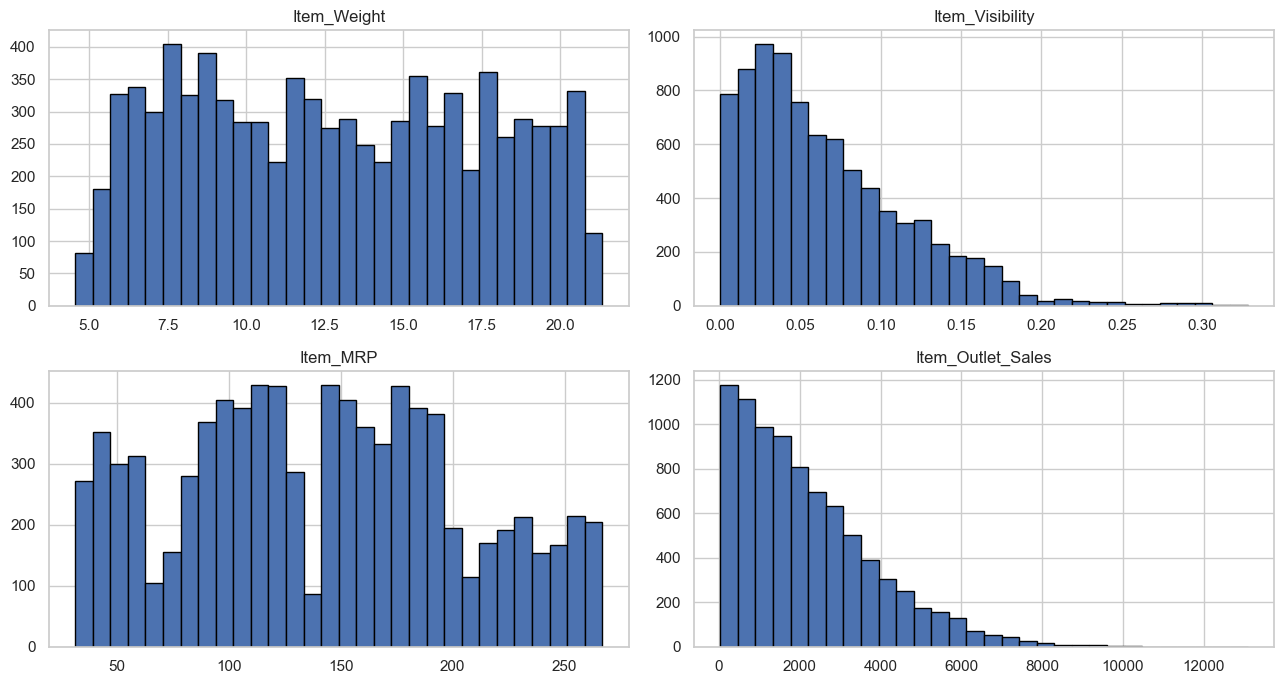

,mean,median,std,min,max,skew
Item_Weight,12.88,12.65,4.64,4.55,21.35,0.07
Item_Visibility,0.07,0.05,0.05,0.00,0.33,1.17
Item_MRP,140.99,143.01,62.27,31.29,266.89,0.13
Item_Outlet_Sales,"2,181.29","1,794.33","1,706.50",33.29,"13,086.97",1.18


In [6]:
num_view = [c for c in ["Item_Weight", "Item_Visibility", "Item_MRP", SALES, "Rating"] if c in clean]

clean[num_view].hist(figsize=(13, 7), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

summary = clean[num_view].agg(["mean", "median", "std", "min", "max"]).T
summary["skew"] = clean[num_view].skew()
display(summary.round(3))

,lower_fence,upper_fence,outliers,outlier_%
Item_Weight,-3.31,28.95,0.00,0.00
Item_Visibility,-0.07,0.20,144.00,1.69
Item_MRP,-43.90,323.37,0.00,0.00
Item_Outlet_Sales,"-2,566.33","6,501.87",186.00,2.18


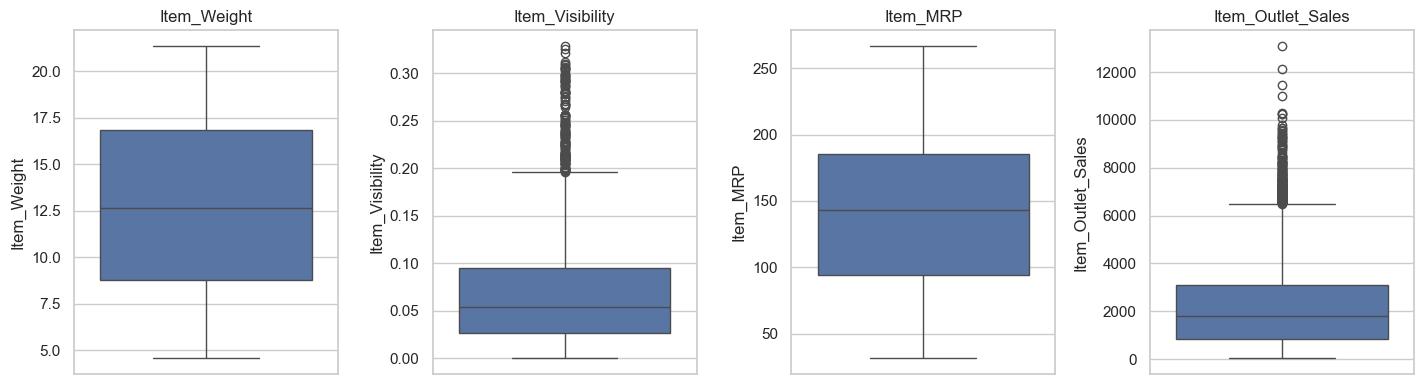

In [7]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (s < low) | (s > high)
    return pd.Series({"lower_fence": low, "upper_fence": high,
                      "outliers": flagged.sum(), "outlier_%": flagged.mean() * 100})

display(pd.DataFrame({c: iqr_outliers(clean[c]) for c in num_view}).T.round(2))

fig, axes = plt.subplots(1, len(num_view), figsize=(3.6 * len(num_view), 4))
for ax, c in zip(np.atleast_1d(axes), num_view):
    sns.boxplot(y=clean[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

## 7. Sales at a glance

A baseline before comparing groups. Each row in this data is an item-outlet record, so "average sales" below means the average per record, not per order or per day.

In [8]:
print(f"Total sales:              {clean[SALES].sum():,.0f}")
print(f"Average sales per record: {clean[SALES].mean():,.2f}")
print(f"Median sales per record:  {clean[SALES].median():,.2f}")
for col in ["Item_Identifier", "Outlet_Identifier"]:
    if col in clean:
        print(f"Unique {col}: {clean[col].nunique():,}")
if "Rating" in clean:
    print(f"Average rating:           {clean['Rating'].mean():.2f}")

Total sales:              18,591,125
Average sales per record: 2,181.29
Median sales per record:  1,794.33
Unique Item_Identifier: 1,559
Unique Outlet_Identifier: 10


## 8. Product categories

First I define two small helpers that I reuse for every group comparison. A category can have a big total just because it has more rows, so each table shows total, average, median, record count and share of total sales side by side.

In [9]:
def segment_summary(col):
    out = clean.groupby(col, dropna=False)[SALES].agg(
        total="sum", average="mean", median="median", records="count")
    out["share_%"] = out["total"] / out["total"].sum() * 100
    return out.sort_values("total", ascending=False)


def plot_segment(col, table):
    labels = table.index.astype(str)
    fig, axes = plt.subplots(1, 2, figsize=(14, max(3.5, 0.45 * len(table))))
    sns.barplot(x=table["total"].values, y=labels, ax=axes[0], color="#4c8bf5", orient="h")
    axes[0].set_title(f"Total sales by {col}")
    sns.barplot(x=table["average"].values, y=labels, ax=axes[1], color="#f5a623", orient="h")
    axes[1].set_title(f"Average sales per record by {col}")
    plt.tight_layout()
    plt.show()

,total,average,median,records,share_%
Item_Type,,,,,
Fruits and Vegetables,"2,820,059.82","2,289.01","1,830.95",1232,15.17
Snack Foods,"2,732,786.09","2,277.32","1,944.14",1200,14.70
Household,"2,055,493.71","2,258.78","1,981.42",910,11.06
Frozen Foods,"1,825,734.79","2,132.87","1,687.14",856,9.82
Dairy,"1,522,594.05","2,232.54","1,650.85",682,8.19
Canned,"1,444,151.49","2,225.19","1,860.25",649,7.77
Baking Goods,"1,265,525.34","1,952.97","1,577.95",648,6.81
Health and Hygiene,"1,045,200.14","2,010.00","1,669.49",520,5.62
Meat,"917,565.61","2,158.98","1,829.62",425,4.94


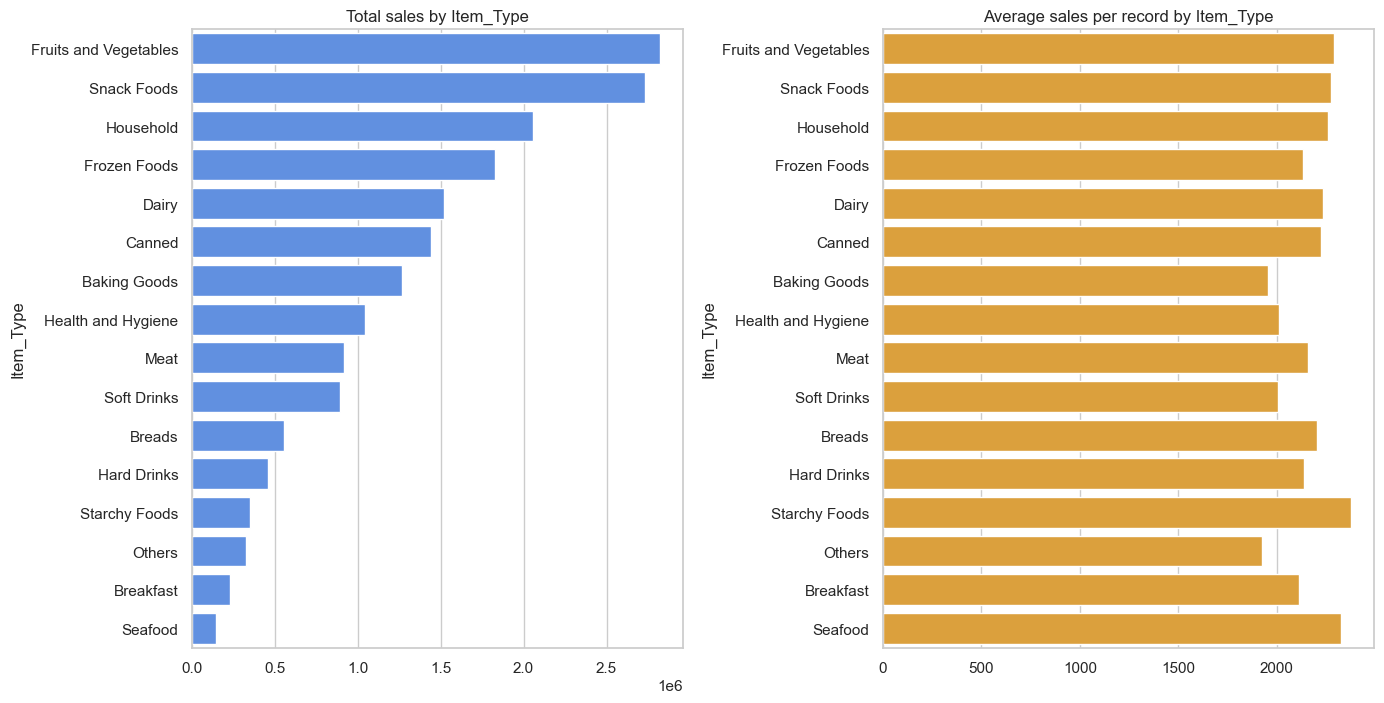

In [10]:
if "Item_Type" in clean:
    item_type_table = segment_summary("Item_Type")
    display(item_type_table.round(2))
    plot_segment("Item_Type", item_type_table)

## 9. Outlet type, size and location

The same comparison for the outlet columns. `Unknown` in outlet size is the group I created for outlets with no size recorded.


Outlet_Type


,total,average,median,records,share_%
Outlet_Type,,,,,
Supermarket Type1,"12,917,342.26","2,316.18","1,990.74",5577,69.48
Supermarket Type3,"3,453,926.05","3,694.04","3,364.95",935,18.58
Supermarket Type2,"1,851,822.83","1,995.50","1,655.18",928,9.96
Grocery Store,"368,034.27",339.83,257.00,1083,1.98


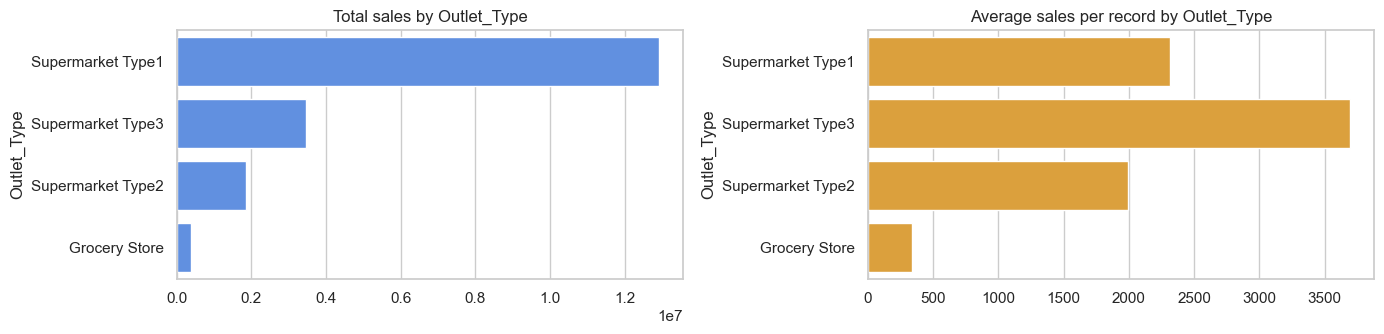


Outlet_Size


,total,average,median,records,share_%
Outlet_Size,,,,,
Medium,"7,489,718.69","2,681.60","2,251.07",2793,40.29
Small,"4,566,212.20","1,912.15","1,544.66",2388,24.56
Unknown,"4,392,530.94","1,822.63","1,443.45",2410,23.63
High,"2,142,663.58","2,299.00","2,050.66",932,11.53


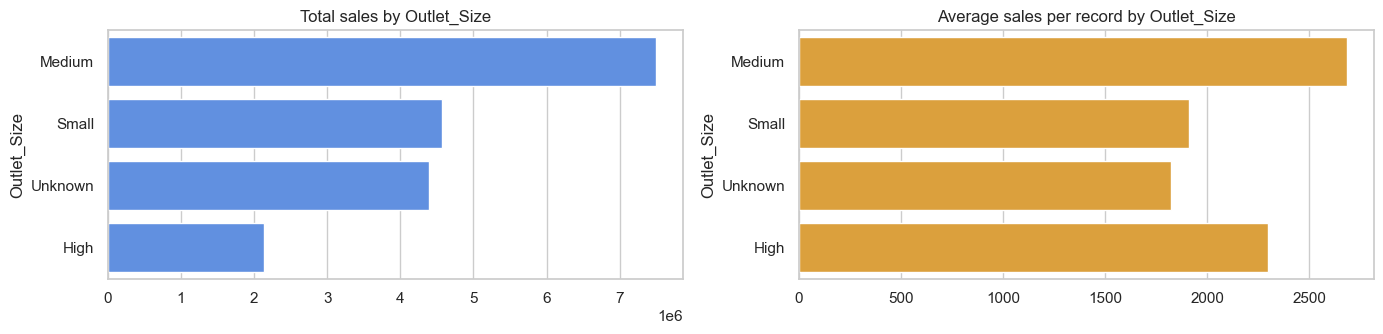


Outlet_Location_Type


,total,average,median,records,share_%
Outlet_Location_Type,,,,,
Tier 3,"7,636,752.63","2,279.63","1,812.31",3350,41.08
Tier 2,"6,472,313.71","2,323.99","2,004.06",2785,34.81
Tier 1,"4,482,059.07","1,876.91","1,487.40",2388,24.11


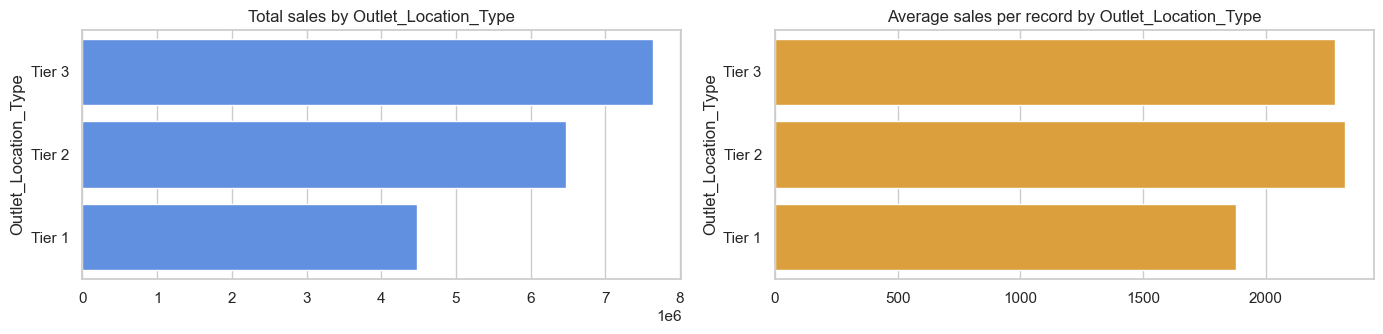

In [11]:
for col in ["Outlet_Type", "Outlet_Size", "Outlet_Location_Type"]:
    if col in clean:
        table = segment_summary(col)
        print(f"\n{col}")
        display(table.round(2))
        plot_segment(col, table)

## 10. Price, visibility and sales

Scatter plots with Pearson and Spearman correlations. Spearman is useful here because it doesn't mind skewed data. These show association, not cause and effect.

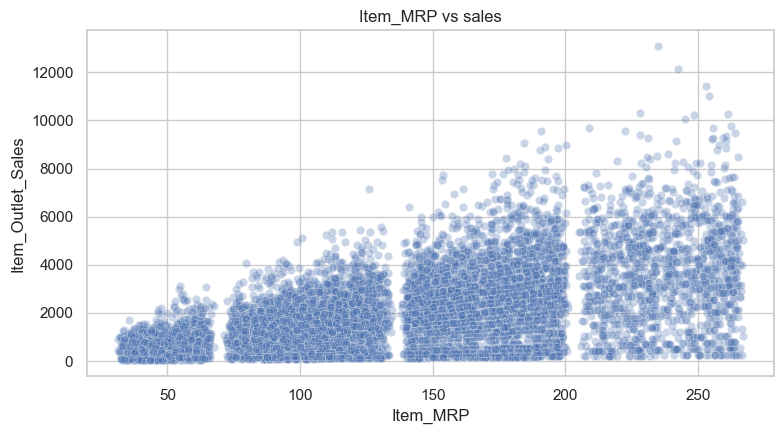

Pearson: 0.568   Spearman: 0.563


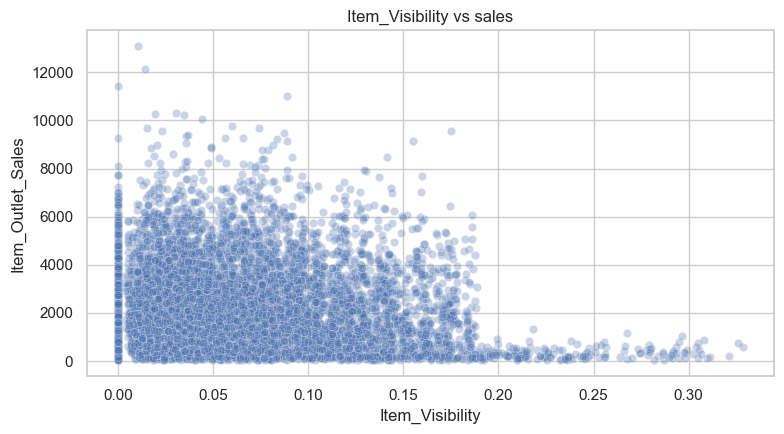

Pearson: -0.129   Spearman: -0.115
Rows with zero visibility: 526


In [12]:
def scatter_vs_sales(col):
    tmp = clean[[col, SALES]].dropna()
    plt.figure(figsize=(8, 4.5))
    sns.scatterplot(data=tmp, x=col, y=SALES, alpha=0.3)
    plt.title(f"{col} vs sales")
    plt.tight_layout()
    plt.show()
    print(f"Pearson: {tmp[col].corr(tmp[SALES]):.3f}   Spearman: {tmp[col].corr(tmp[SALES], method='spearman'):.3f}")


for col in ["Item_MRP", "Item_Visibility"]:
    if col in clean:
        scatter_vs_sales(col)

if "Item_Visibility" in clean:
    print("Rows with zero visibility:", (clean["Item_Visibility"] == 0).sum())

## 11. Combinations of segments

Heatmaps to see whether a pattern holds across groups or only shows up in some of them. Blank cells just mean there are no records for that combination.

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Outlet_Size,,,,
High,NaN,"2,299.00",NaN,NaN
Medium,NaN,"2,348.35","1,995.50","3,694.04"
Small,340.33,"2,358.34",NaN,NaN
Unknown,339.35,"2,266.41",NaN,NaN


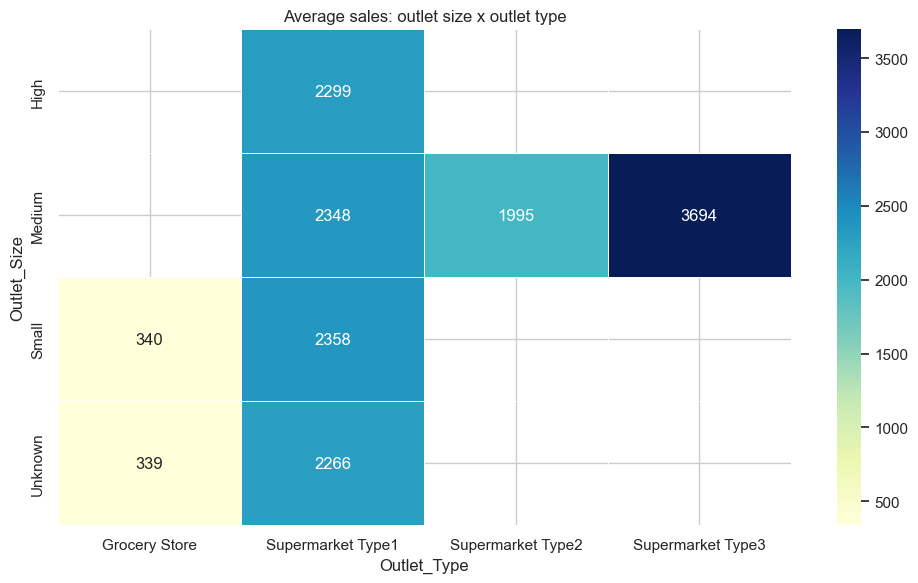

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Outlet_Location_Type,,,,
Tier 1,340.33,"2,313.10",NaN,NaN
Tier 2,NaN,"2,323.99",NaN,NaN
Tier 3,339.35,"2,299.00","1,995.50","3,694.04"


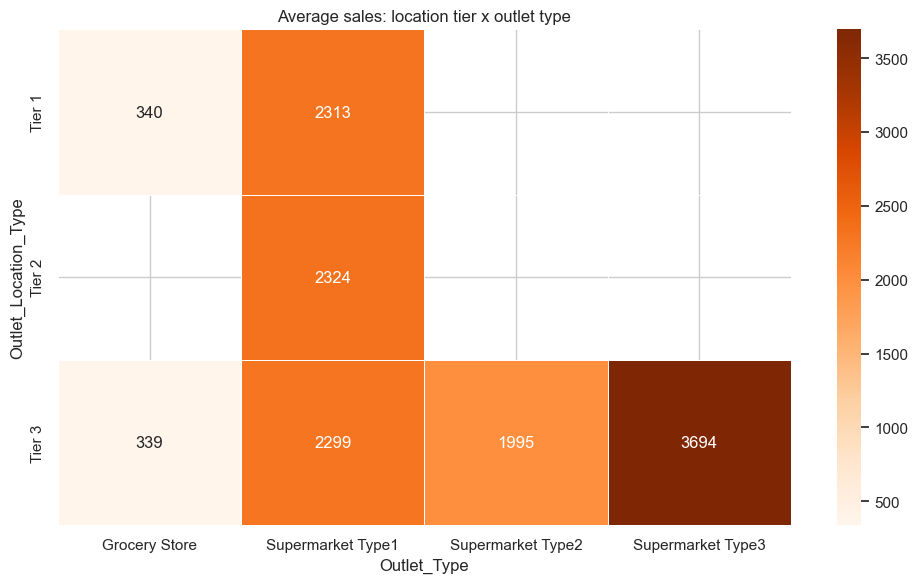

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item_Type,,,,
Baking Goods,"24,827.02","895,461.05","121,065.08","224,172.20"
Breads,"12,604.93","375,508.54","54,604.92","110,518.81"
Breakfast,"7,843.79","151,526.76","22,496.05","50,432.35"
Canned,"25,759.14","1,000,560.25","145,681.70","272,150.41"
Dairy,"31,451.73","1,076,694.48","152,130.64","262,317.21"
Frozen Foods,"33,195.46","1,292,668.01","183,599.01","316,272.31"
Fruits and Vegetables,"48,602.07","1,931,957.85","263,471.71","576,028.19"
Hard Drinks,"5,835.74","323,554.17","49,445.64","78,957.89"
Health and Hygiene,"24,515.42","712,754.88","108,845.65","199,084.19"


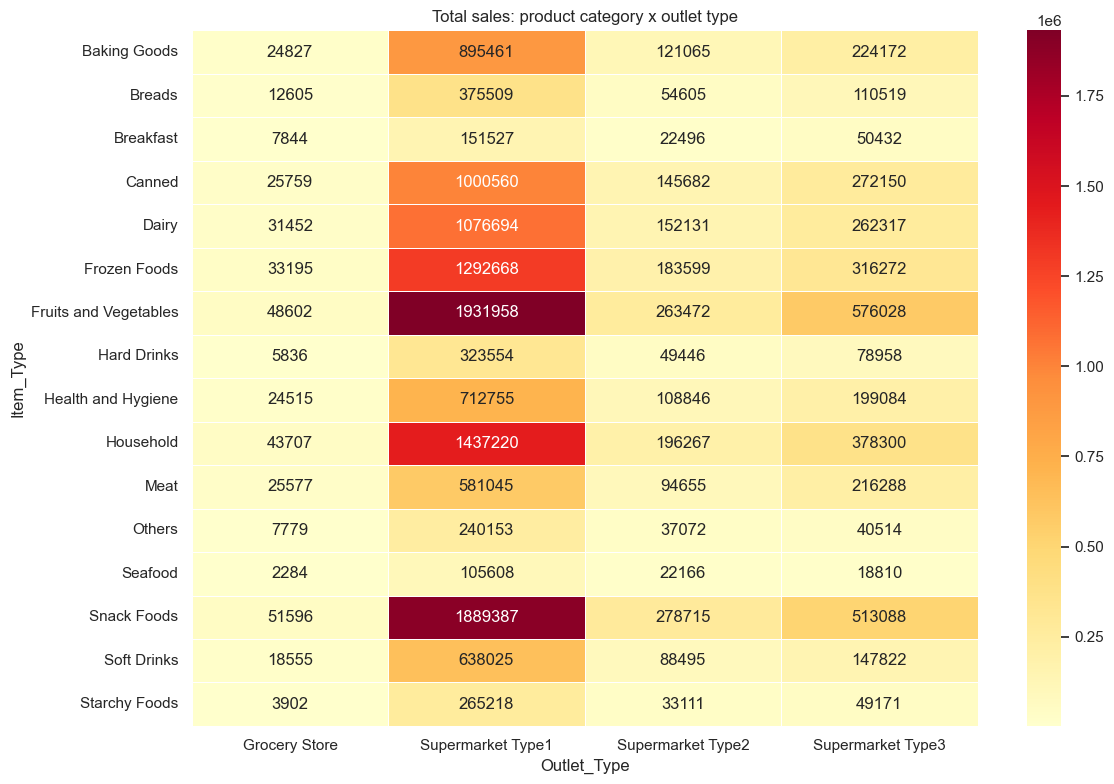

In [13]:
def heatmap(index, columns, agg, cmap, title, size=(10, 6)):
    if not {index, columns} <= set(clean.columns):
        return
    pivot = clean.pivot_table(values=SALES, index=index, columns=columns,
                              aggfunc=agg, observed=False)
    display(pivot.round(2))
    plt.figure(figsize=size)
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap=cmap, linewidths=0.5)
    plt.title(title)
    plt.tight_layout()
    plt.show()


heatmap("Outlet_Size", "Outlet_Type", "mean", "YlGnBu", "Average sales: outlet size x outlet type")
heatmap("Outlet_Location_Type", "Outlet_Type", "mean", "Oranges", "Average sales: location tier x outlet type")
heatmap("Item_Type", "Outlet_Type", "sum", "YlOrRd", "Total sales: product category x outlet type", size=(12, 8))

## 12. Correlation between numeric columns

A quick matrix of how the numeric columns move together.

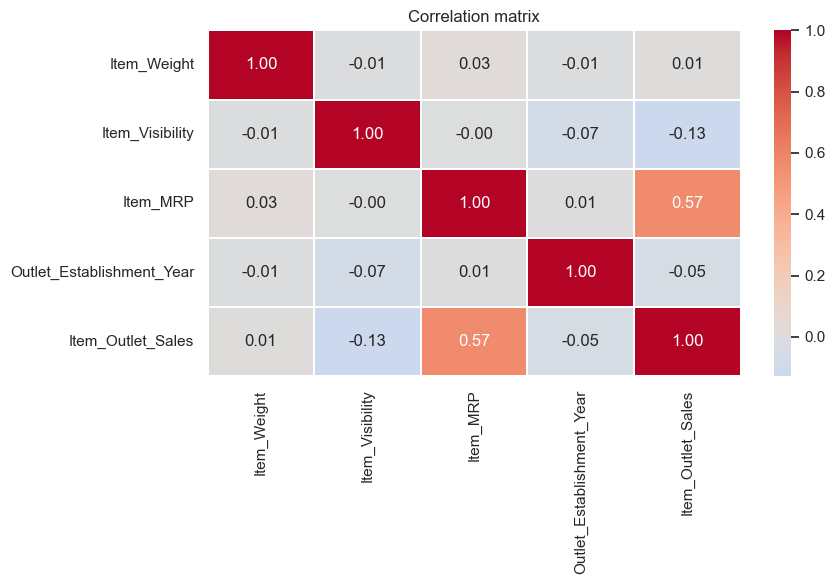

In [14]:
corr = clean.select_dtypes(include=np.number).corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 13. Outlet establishment year

This data is a snapshot, not a time series, so I read this chart as "sales by when the outlet opened" and not as growth over time.

,total,average,records
Outlet_Establishment_Year,,,
1985,"3,633,620.14","2,483.68",1463
1987,"2,142,663.58","2,299.00",932
1997,"2,118,395.17","2,277.84",930
1998,"188,340.17",339.35,555
1999,"2,183,969.81","2,348.35",930
2002,"2,036,725.48","2,192.38",929
2004,"2,268,122.94","2,438.84",930
2007,"2,167,465.29","2,340.68",926
2009,"1,851,822.83","1,995.50",928


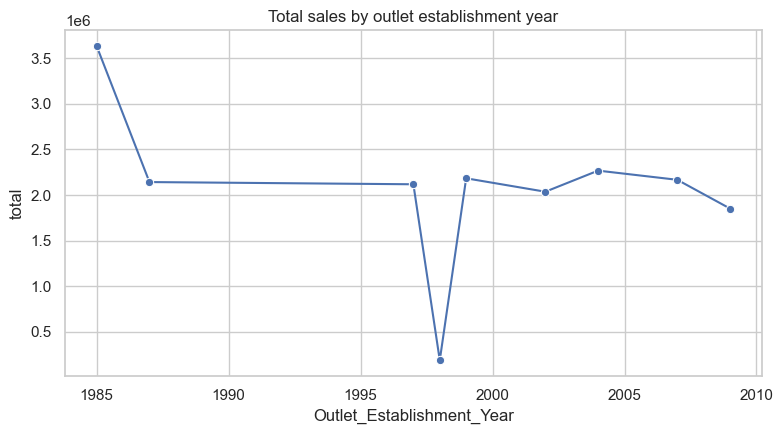

In [15]:
if "Outlet_Establishment_Year" in clean:
    by_year = clean.groupby("Outlet_Establishment_Year")[SALES].agg(
        total="sum", average="mean", records="count")
    display(by_year.round(2))
    plt.figure(figsize=(8, 4.5))
    sns.lineplot(data=by_year.reset_index(), x="Outlet_Establishment_Year", y="total", marker="o")
    plt.title("Total sales by outlet establishment year")
    plt.tight_layout()
    plt.show()

## 14. Does sales differ by outlet size? (Kruskal-Wallis test)

The charts suggest some differences, so I check with a test that doesn't assume normal data. A small p-value says at least one group's sales distribution differs from the others. It doesn't say which one, and it doesn't prove that size is the cause.

In [16]:
if "Outlet_Size" in clean:
    known = clean[clean["Outlet_Size"] != "Unknown"]
    groups = {name: g[SALES].dropna() for name, g in known.groupby("Outlet_Size")}
    stat, p = kruskal(*groups.values())
    print("Groups:", list(groups))
    print(f"Statistic: {stat:.3f}, p-value: {p:.4g}")
    print("Evidence of a difference between groups." if p < 0.05 else "No clear evidence of a difference.")

Groups: ['High', 'Medium', 'Small']
Statistic: 283.777, p-value: 2.391e-62
Evidence of a difference between groups.


## 15. Findings

### 1. Product Categories & Top-Selling Items
- **Evidence:** Fruits & Vegetables ($2.82M, 15.17% share) and Snack Foods ($2.73M, 14.70% share) are the highest revenue contributors, together generating 29.87% ($5.55M) of total recorded sales. Top-selling individual items (led by FDY55 at $42,661.80, FDA15 at $41,584.54, and FDZ20 at $40,185.02) consistently have list prices exceeding $224 MRP (well above the dataset average MRP of $140.99) and appear across 6 to 9 outlet locations.
- **What it suggests:** High-MRP everyday staples and snacks drive the bulk of revenue. Inventory replenishment and stock availability for these top products directly dictate outlet topline performance.
- **What I'd look into next:** Calculate unit turnover velocity (estimated sales / MRP) across categories to determine whether category leaders succeed primarily due to high item volume or higher unit price.

### 2. Outlet Performance: Volume vs. Average Efficiency
- **Evidence:** Supermarket Type 1 accounts for 69.48% of total revenue ($12.92M across 6 outlets, averaging $2,316.18 per record). However, Supermarket Type 3 (OUT027) exhibits the highest operational efficiency by far, averaging $3,694.04 per record (median: $3,345.99) with total sales of $3.45M across 935 items. Grocery Stores (OUT010, OUT019) average only $339.83 per item. Medium-sized outlets achieve higher median sales ($2,251.06) than High ($2,050.66) and Small ($1,544.66) outlets (Kruskal-Wallis H = 283.78, p = 2.39e-62).
- **What it suggests:** Total sales are driven by store footprint count (6 Type 1 stores), but sales density per item is highest in Supermarket Type 3 and Medium-format stores. Small grocery stores operate with drastically lower sales volumes.
- **What I'd look into next:** Deconstruct category-level sales within OUT027 to see if its premium performance stems from a superior product mix, higher inventory depth, or local customer footfall.

### 3. Price and Visibility Dynamics
- **Evidence:** `Item_MRP` shows a moderate-to-strong positive correlation with `Item_Outlet_Sales` (Pearson r = 0.5676, Spearman rho = 0.5630). Conversely, `Item_Visibility` displays a weak negative correlation (Pearson r = -0.1286, Spearman rho = -0.1151). Across establishment years, outlets founded in 1985 generated both the highest average sales ($3,694 in OUT027) and the lowest ($340 in OUT019).
- **What it suggests:** Maximum Retail Price is one of the strongest individual predictors of revenue per record. Allocating greater display area does not automatically produce higher sales. Furthermore, store format (Supermarket vs. Grocery Store) is the dominant factor rather than outlet age.
- **What I'd look into next:** Investigate whether low-selling items were intentionally given higher visibility to stimulate demand, and check the impact of zero-visibility records on correlation metrics.

### 4. Data Quality & Cleaning Impact
- **What was missing or messy, what I changed, and how it could affect the results:**
  - `Item_Fat_Content` contained inconsistent entries (`LF`, `low fat`, `reg`), which were standardized into 'Low Fat' (64.73%, 5,517 records) and 'Regular' (35.27%, 3,006 records).
  - Missing values occurred in `Item_Weight` (1,463 rows, 17.17%) and `Outlet_Size` (2,410 rows, 28.28% across OUT010, OUT017, and OUT045).
  - No duplicate rows were present (0 out of 8,523).
  - Missing outlet sizes were preserved as a distinct group during size-based comparisons to prevent imputation bias.

### Limitations
This analysis utilizes a static cross-sectional dataset and is descriptive in nature. The dataset does not contain individual transaction-level baskets, timestamps, or customer identifiers; therefore, conclusions reflect product- and outlet-level aggregations rather than individual customer purchasing behavior or temporal trends.


In [17]:
# Input features
X = df[
    [
        "Item_Weight",
        "Item_Fat_Content",
        "Item_Visibility",
        "Item_Type",
        "Item_MRP",
        "Outlet_Establishment_Year",
        "Outlet_Size",
        "Outlet_Location_Type",
        "Outlet_Type"
    ]
]

# Output / target
y = df["Item_Outlet_Sales"]

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestRegressor

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer




X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


In [23]:
new_record = pd.DataFrame([{
    "Item_Weight": 12.0,
    "Item_Fat_Content": "Low Fat",
    "Item_Visibility": 0.05,
    "Item_Type": "Snack Foods",
    "Item_MRP": 150.0,
    "Outlet_Establishment_Year": 2004,
    "Outlet_Size": "Medium",
    "Outlet_Location_Type": "Tier 2",
    "Outlet_Type": "Supermarket Type1"
}])
rf = RandomForestRegressor(n_estimators=100)
rf.fit(X_train,y_train)


print("Predicted Sales:", predicted_sales[0])

ValueError: could not convert string to float: 'Regular'